# Énumération Hückel — version parallèle (multiprocessing)

Même logique que `enumeration_huckel.ipynb` mais la génération des voisins
(`find_neighbors`) est répartie sur **N_CPU cœurs** via `multiprocessing`.

**Stratégie** : BFS par *vagues*. À chaque vague, toute la frontière est
explorée en parallèle ; la vérification de validité reste séquentielle
(paralléliser la validité était plus lent, cf. commentaires dans `enumeration.py`).

> **Note macOS / Jupyter** : on utilise `fork` comme méthode de démarrage
> des processus pour éviter les problèmes de `spawn` dans un kernel Jupyter.

In [1]:
import multiprocessing
import os
import sys
import time
import pathlib

# --- Localisation de la racine du projet ---
def _find_project_root() -> pathlib.Path:
    try:
        return pathlib.Path(__vsc_ipynb_file__).resolve().parent.parent  # type: ignore[name-defined]
    except NameError:
        pass
    try:
        return pathlib.Path(__file__).resolve().parent.parent
    except NameError:
        pass
    candidates = [
        pathlib.Path.cwd(),
        pathlib.Path.cwd().parent,
        pathlib.Path.home() / "Desktop" / "LeaMol",
    ]
    for start in candidates:
        here = start.resolve()
        for _ in range(5):
            if (here / "setup.py").exists():
                return here
            here = here.parent
    raise RuntimeError("Impossible de localiser la racine du projet LeaMol.")

project_root = str(_find_project_root())
os.chdir(project_root)
if project_root not in sys.path:
    sys.path.insert(0, project_root)
sys.path.insert(0, os.path.join(project_root, "scripts", "Lea"))  # huckel_filters

print(f"project_root : {project_root}")

from evomol import default_parameters as dp
from evomol.evaluation.evaluation import Evaluation, EvaluationError
from evomol.evaluation.huckel import Huckel, HuckelCompatible
from huckel_filters import HeteroatomChainFilter
from evomol.representation import MolecularGraph, Molecule
from evomol.search.enumeration import find_neighbors
from evomol.visualization.draw_mol import draw_multiple_svgs_in_matplotlib, mol_to_svg

project_root : /Users/LeaClautour/Desktop/LeaMol


## Paramètres

In [2]:
STARTING_SMILES = "C=C"
MAX_SECONDS     = 60.0
MAX_HEAVY_ATOMS = 10
UNIQUE_KEKULE   = False        # True : un seul SMILES par molécule aromatique (plus lent)
MAX_RING_N      = 3
USE_CHEMBL_ZINC = True
N_CPU           = 3            # nombre de cœurs

ACCEPTED_ATOMS = ["C", "N", "O", "S", "F", "Cl", "Br"]

## Initialisation

In [3]:
dp.setup_default_parameters(
    accepted_atoms=ACCEPTED_ATOMS,
    max_heavy_atoms=MAX_HEAVY_ATOMS,
    unique_kekule=UNIQUE_KEKULE,
)
dp.setup_default_action_space()

filters: list[Evaluation] = [
    HuckelCompatible(),
    HeteroatomChainFilter(max_ring_n=MAX_RING_N),
]
if USE_CHEMBL_ZINC:
    filters += dp.setup_filters("chembl_zinc")

print(f"Filtres actifs : {[f.name for f in filters]}")
print(f"Cœurs utilisés : {N_CPU}")

Filtres actifs : ['huckel_compatible', 'heteroatom_chain_filter', 'UnknownGCF_chembl_zinc', 'FilterUnknownGCF', 'UnknownECFP_chembl_zinc', 'FilterUnknownECFP']
Cœurs utilisés : 3


## Énumération parallèle — stratégie *two-phase*

**Point bloquant identifié** : le goulot d'étranglement n'est PAS la génération des voisins mais la **validation** (filtres GCF + ECFP4). Il y a ~20× plus de molécules invalides que valides, et chaque validation fait du fingerprinting RDKit coûteux. Paralléliser uniquement `find_neighbors` n'apportait donc aucun gain — seulement de l'overhead.

**Solution** : à chaque vague BFS, deux phases parallèles sur `N_CPU` cœurs.

```
Phase A (∥)   : chaque source → ses voisins          (génération)
   ↓ maître   : union + dédup contre `seen`          (chaque candidat 1 seule fois)
Phase B (∥)   : chaque candidat unique → valide ?    (validation = le vrai coût)
   ↓ maître   : valides → frontière suivante
```

**Pourquoi `fork` est essentiel** : les filtres (bases GCF/ECFP déjà chargées en mémoire) sont **hérités par les workers via copy-on-write**, sans rechargement ni re-sérialisation. C'est ce qui rend la parallélisation de la validation rentable (contrairement à `spawn`, où chaque worker rechargerait les bases — d'où le commentaire « plus lent » dans `enumeration.py`).

In [4]:
# =========================================================================
#  Fonctions exécutées dans les workers (héritées via fork).
#  _WORKER_FILTERS est rempli dans le parent AVANT la création du pool ;
#  le fork le copie dans chaque worker → pas de re-sérialisation des bases.
# =========================================================================
_WORKER_FILTERS: list = []


def _gen_neighbors(source_smi: str) -> tuple[str, list[str]]:
    """Phase A (worker) : voisins de profondeur 1 d'une molécule source."""
    return source_smi, list(find_neighbors(Molecule(source_smi), 1))


def _validate(smi: str) -> tuple[str, bool]:
    """Phase B (worker) : la molécule passe-t-elle tous les filtres ?"""
    mol = Molecule(smi)
    for ev in _WORKER_FILTERS:
        try:
            ev.evaluate(mol)
        except EvaluationError:
            return smi, False
    return smi, True


def _is_valid(mol: Molecule, evals: list[Evaluation]) -> bool:
    """Validation séquentielle (utilisée seulement pour le point de départ)."""
    for ev in evals:
        try:
            ev.evaluate(mol)
        except EvaluationError:
            return False
    return True


def enumerate_huckel_parallel(
    starting_smiles: str,
    max_seconds: float,
    evals: list[Evaluation],
    n_cpu: int,
) -> tuple[list[dict], set[str], bool]:
    """BFS par vagues, génération ET validation parallélisées (two-phase).

    Chaque candidat est validé exactement une fois (dédup en maître avant la
    phase B), exactement comme la version séquentielle — mais réparti sur n_cpu
    cœurs. La deadline est vérifiée pendant la validation (le plus long).

    Retourne (discovery_log, found_invalid, completed).
    """
    global _WORKER_FILTERS
    _WORKER_FILTERS = evals  # hérité par les workers au moment du fork

    deadline = time.time() + max_seconds
    seen: set[str] = set()
    discovery_log: list[dict] = []
    found_invalid: set[str] = set()

    mol = Molecule(starting_smiles)
    canonical = mol.get_representation(MolecularGraph).canonical_smiles
    seen.add(canonical)

    if _is_valid(mol, evals):
        discovery_log.append({"rank": 0, "wave": 0, "smiles": canonical, "parent": None})
        frontier: list[str] = [canonical]
    else:
        found_invalid.add(canonical)
        frontier = []

    ctx = multiprocessing.get_context("fork")
    wave = 0
    stopped = False

    with ctx.Pool(n_cpu) as pool:
        while frontier:
            if time.time() >= deadline:
                stopped = True
                break
            wave += 1

            # ---------- Phase A : génération parallèle des voisins ----------
            cs_a = max(1, len(frontier) // (n_cpu * 4))
            candidates: list[str] = []
            parent_of: dict[str, str] = {}
            for source, neighbors in pool.imap(_gen_neighbors, frontier, chunksize=cs_a):
                for smi in neighbors:
                    if smi not in seen:
                        seen.add(smi)
                        candidates.append(smi)
                        parent_of[smi] = source
                if time.time() >= deadline:
                    stopped = True
                    break
            if stopped:
                break

            # ---------- Phase B : validation parallèle (le vrai coût) ----------
            cs_b = max(1, len(candidates) // (n_cpu * 4))
            next_frontier: list[str] = []
            for smi, ok in pool.imap(_validate, candidates, chunksize=cs_b):
                if ok:
                    discovery_log.append({
                        "rank":   len(discovery_log),
                        "wave":   wave,
                        "smiles": smi,
                        "parent": parent_of[smi],
                    })
                    next_frontier.append(smi)
                else:
                    found_invalid.add(smi)
                if time.time() >= deadline:
                    stopped = True
                    break

            frontier = next_frontier
            if stopped:
                break

    completed = not stopped
    return discovery_log, found_invalid, completed


# --- Lancement ---
print(f"Départ : '{STARTING_SMILES}'  |  limite : {MAX_SECONDS}s  |  cœurs : {N_CPU}")
t0 = time.time()

discovery_log, found_invalid, completed = enumerate_huckel_parallel(
    STARTING_SMILES, MAX_SECONDS, filters, N_CPU
)

elapsed = time.time() - t0
status = "terminée" if completed else "arrêtée (limite de temps)"
found_valid = {entry["smiles"] for entry in discovery_log}

print(f"\nStatut    : {status}")
print(f"Durée     : {elapsed:.1f}s")
print(f"Valides   : {len(found_valid)}")
print(f"Invalides : {len(found_invalid)}")
print(f"Débit     : {(len(found_valid) + len(found_invalid)) / elapsed:.0f} molécules/s")

Départ : 'C=C'  |  limite : 60.0s  |  cœurs : 3

Statut    : arrêtée (limite de temps)
Durée     : 72.4s
Valides   : 4229
Invalides : 89084
Débit     : 1289 molécules/s


## Ordre de découverte

`wave` = numéro de vague BFS (toutes les molécules d'une même vague sont
équidistantes du point de départ).  
`rank` = ordre absolu de découverte au sein de toutes les vagues.

## Diagnostic : pourquoi tant de molécules invalides ?

Le run précédent a produit ~95 % de molécules invalides (89 083 invalides pour 4 229 valides).
Avant de changer les règles de mutation, il faut savoir **quel filtre rejette le plus**
et **quelle action génère le plus d'invalides**.

Les filtres sont appliqués dans cet ordre (court-circuit dès le premier échec) :
1. `huckel_compatible` — vérification structurale légère
2. `heteroatom_chain_filter` — règles sur les hétéroatomes consécutifs
3. `UnknownGCF` + `FilterUnknownGCF` — sous-graphes cycliques rares (ChEMBL/ZINC)
4. `UnknownECFP` + `FilterUnknownECFP` — fingerprints ECFP4 rares (ChEMBL/ZINC)

Si `huckel_compatible` est le premier filtre à échouer pour la majorité des candidats,
alors **changer l'espace d'action** est la bonne stratégie (moins de molécules générées
ne passant pas Hückel → moins de travail inutile).

Échantillon analysé : 5000 molécules invalides

Filtre                                Rejets       %
───────────────────────────────────────────────────────
  FilterUnknownECFP                     2505   50.1%
  huckel_compatible                     2028   40.6%
  FilterUnknownGCF                       297    5.9%
  heteroatom_chain_filter                170    3.4%


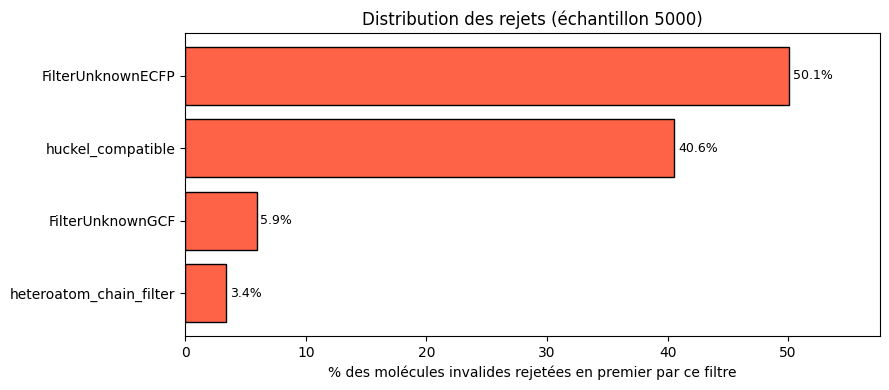

In [5]:
import matplotlib.pyplot as plt
from collections import Counter

# ── Profil des rejets : quel filtre échoue en premier ? ──────────────────────
# On analyse les molécules invalides déjà trouvées (found_invalid).
# On les passe à travers les filtres un par un et on enregistre le premier échec.
# Pour rester rapide, on limite à un échantillon de 5 000 molécules.

SAMPLE_SIZE = 5_000
sample = list(found_invalid)[:SAMPLE_SIZE]

rejection_counts: Counter = Counter()
for smi in sample:
    mol = Molecule(smi)
    for ev in filters:
        try:
            ev.evaluate(mol)
        except EvaluationError:
            rejection_counts[ev.name] += 1
            break

total_sampled = len(sample)
print(f"Échantillon analysé : {total_sampled} molécules invalides\n")
print(f"{'Filtre':<35} {'Rejets':>8}  {'%':>6}")
print("─" * 55)
for name, count in rejection_counts.most_common():
    print(f"  {name:<33} {count:>8}  {100*count/total_sampled:>5.1f}%")

# ── Graphique ─────────────────────────────────────────────────────────────────
names  = [n for n, _ in rejection_counts.most_common()]
counts = [c for _, c in rejection_counts.most_common()]
pcts   = [100 * c / total_sampled for c in counts]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(names[::-1], pcts[::-1], color="tomato", edgecolor="black")
for bar, pct in zip(bars, pcts[::-1]):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f"{pct:.1f}%", va="center", fontsize=9)
ax.set_xlabel("% des molécules invalides rejetées en premier par ce filtre")
ax.set_title(f"Distribution des rejets (échantillon {total_sampled})")
ax.set_xlim(0, max(pcts) * 1.15)
plt.tight_layout()
plt.show()

## Espace d'action optimisé pour Hückel

### Pourquoi `huckel_compatible` échoue si souvent

Deux actions sont quasi-systématiquement responsables des carbones sp3 non-terminaux
(la cause principale d'incompatibilité Hückel) :

| Action | Ce qu'elle fait | Problème Hückel |
|--------|-----------------|-----------------|
| `InsertCarbonMG` | Insère un –CH₂– entre deux atomes liés par une **liaison simple** | Le C inséré est sp3, non-terminal → rejet immédiat |
| `ChangeBondMG` (réduction) | Réduit une liaison double en simple (C=C → C–C) | Crée un C sp3 au milieu d'une chaîne → rejet |

### Modifications proposées

```python
# 1. Supprimer InsertCarbonMG : presque jamais utile pour l'espace Hückel
MolecularGraph.action_space = [a for a in MolecularGraph.action_space
                                if a is not mg.InsertCarbonMG]

# 2. Empêcher la réduction de liaison (avoid_bond_breaking = True)
#    → ChangeBondMG ne peut plus passer de double/triple → simple
#    → Seuls les incréments de liaison et la suppression totale (bond=0)
#      sur liaisons non-pont restent autorisés
mg.ChangeBondMG.avoid_bond_breaking = True
```

Ces deux changements **ne réduisent pas la diversité chimique** atteignable :
- `InsertCarbonMG` peut toujours être simulé par `AddAtomMG` + 2× `ChangeBondMG`
- Réduire une double liaison crée systématiquement un voisin invalide ;
  l'espace valide est de toute façon inaccessible par ce chemin

Espace d'action optimisé :
  AddAtomMG
  ChangeBondMG
  CutAtomMG
  MoveGroupMG
  RemoveAtomMG
  SubstituteAtomMG

ChangeBondMG.avoid_bond_breaking = True

Départ : 'C=C'  |  limite : 60.0s  |  cœurs : 3

                                 Espace original   Espace optimisé
────────────────────────────────────────────────────────────────────
  Durée (s)                                 72.4              60.9
  Valides                                   4229              4427
  Invalides                                89084             94141
  % invalides                              95.5%             95.5%
  Débit (mol/s)                             1289              1618
  Débit valides/s                           58.4              72.7


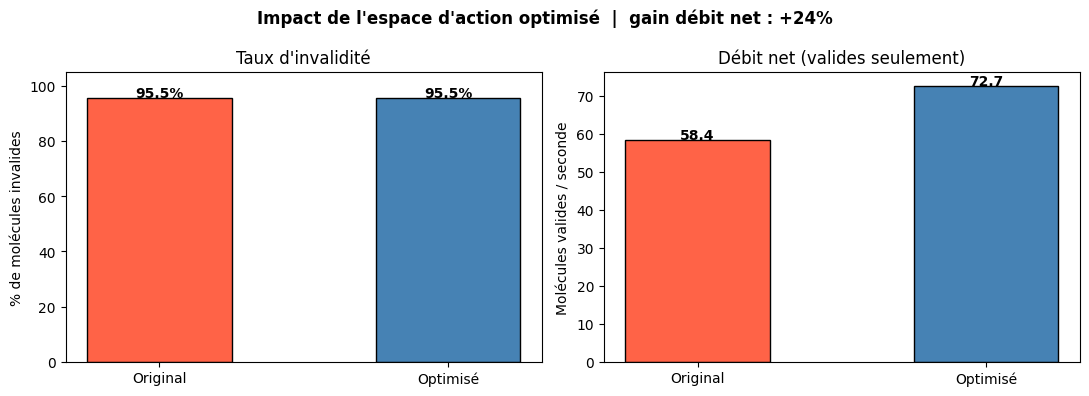

In [6]:
from evomol.action import molecular_graph as mg
from evomol.representation import MolecularGraph

# ── Espace d'action optimisé pour Hückel ────────────────────────────────────

# Réinitialiser depuis les paramètres par défaut
dp.setup_default_parameters(
    accepted_atoms=ACCEPTED_ATOMS,
    max_heavy_atoms=MAX_HEAVY_ATOMS,
    unique_kekule=UNIQUE_KEKULE,
)
dp.setup_default_action_space()

# Modification 1 : supprimer InsertCarbonMG
MolecularGraph.action_space = [
    a for a in MolecularGraph.action_space if a is not mg.InsertCarbonMG
]

# Modification 2 : interdire la réduction de liaison (double→simple)
mg.ChangeBondMG.avoid_bond_breaking = True

print("Espace d'action optimisé :")
for a in MolecularGraph.action_space:
    print(f"  {a.__name__}")
print(f"\nChangeBondMG.avoid_bond_breaking = {mg.ChangeBondMG.avoid_bond_breaking}")

# Reconstruire les filtres (inchangés)
filters_opt: list[Evaluation] = [
    HuckelCompatible(),
    HeteroatomChainFilter(max_ring_n=MAX_RING_N),
]
if USE_CHEMBL_ZINC:
    filters_opt += dp.setup_filters("chembl_zinc")

# ── Run de comparaison (même durée, même départ) ─────────────────────────────
print(f"\nDépart : '{STARTING_SMILES}'  |  limite : {MAX_SECONDS}s  |  cœurs : {N_CPU}")
t0 = time.time()

discovery_log_opt, found_invalid_opt, completed_opt = enumerate_huckel_parallel(
    STARTING_SMILES, MAX_SECONDS, filters_opt, N_CPU
)

elapsed_opt = time.time() - t0
n_valid_opt   = len(discovery_log_opt)
n_invalid_opt = len(found_invalid_opt)
total_opt     = n_valid_opt + n_invalid_opt
ratio_opt     = 100 * n_invalid_opt / total_opt if total_opt else 0

# ── Résultats côte à côte ─────────────────────────────────────────────────────
n_valid_base   = len(found_valid)
n_invalid_base = len(found_invalid)
total_base     = n_valid_base + n_invalid_base
ratio_base     = 100 * n_invalid_base / total_base if total_base else 0

print(f"\n{'':30s}  {'Espace original':>16}  {'Espace optimisé':>16}")
print("─" * 68)
for label, v_base, v_opt in [
    ("Durée (s)",         f"{elapsed:.1f}",       f"{elapsed_opt:.1f}"),
    ("Valides",           str(n_valid_base),       str(n_valid_opt)),
    ("Invalides",         str(n_invalid_base),     str(n_invalid_opt)),
    ("% invalides",       f"{ratio_base:.1f}%",    f"{ratio_opt:.1f}%"),
    ("Débit (mol/s)",     f"{total_base/elapsed:.0f}", f"{total_opt/elapsed_opt:.0f}"),
    ("Débit valides/s",   f"{n_valid_base/elapsed:.1f}", f"{n_valid_opt/elapsed_opt:.1f}"),
]:
    print(f"  {label:<28}  {v_base:>16}  {v_opt:>16}")

# ── Graphique comparatif ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Gauche : taux d'invalidité
labels = ["Original", "Optimisé"]
invalid_pcts = [ratio_base, ratio_opt]
colors = ["tomato", "steelblue"]
bars = axes[0].bar(labels, invalid_pcts, color=colors, edgecolor="black", width=0.5)
for bar, pct in zip(bars, invalid_pcts):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f"{pct:.1f}%", ha="center", fontweight="bold")
axes[0].set_ylabel("% de molécules invalides")
axes[0].set_title("Taux d'invalidité")
axes[0].set_ylim(0, 105)

# Droite : débit en molécules valides/s
valid_rates = [n_valid_base / elapsed, n_valid_opt / elapsed_opt]
bars2 = axes[1].bar(labels, valid_rates, color=colors, edgecolor="black", width=0.5)
for bar, rate in zip(bars2, valid_rates):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
                 f"{rate:.1f}", ha="center", fontweight="bold")
axes[1].set_ylabel("Molécules valides / seconde")
axes[1].set_title("Débit net (valides seulement)")

gain = (valid_rates[1] / valid_rates[0] - 1) * 100 if valid_rates[0] else 0
fig.suptitle(f"Impact de l'espace d'action optimisé  |  gain débit net : {gain:+.0f}%",
             fontweight="bold")
plt.tight_layout()
plt.show()

In [7]:
import pandas as pd

df_order = pd.DataFrame(discovery_log)
print(f"{len(df_order)} molécules valides — 20 premières découvertes :")
df_order.head(20)

4229 molécules valides — 20 premières découvertes :


,rank,wave,smiles,parent
0,0,0,C=C,None
1,1,1,C=CO,C=C
2,2,1,C=CC,C=C
3,3,1,C#C,C=C
4,4,1,C=CCl,C=C
5,5,1,C=O,C=C
6,6,2,C=COC,C=CO
7,7,2,C=NO,C=CO
8,8,2,O=CO,C=CO
9,9,2,COC,C=CO


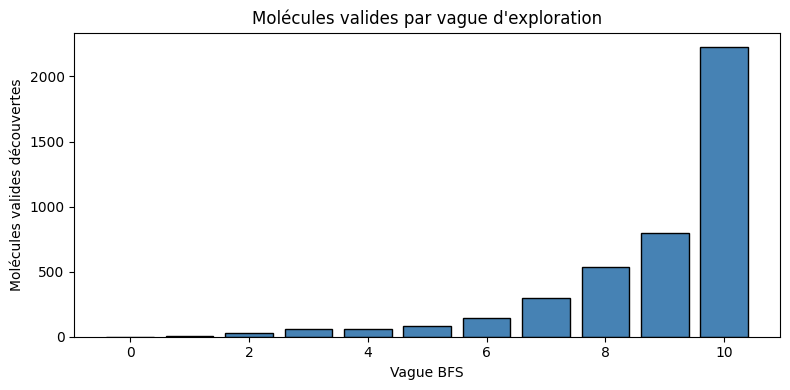

In [8]:
# Nombre de molécules découvertes par vague
import matplotlib.pyplot as plt

wave_counts = df_order.groupby("wave").size()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(wave_counts.index, wave_counts.values, color="steelblue", edgecolor="black")
ax.set_xlabel("Vague BFS")
ax.set_ylabel("Molécules valides découvertes")
ax.set_title("Molécules valides par vague d'exploration")
plt.tight_layout()
plt.show()

Molécules 0 à 29 dans l'ordre de découverte :

  rank    0  wave   0  C=C                                       ← None
  rank    1  wave   1  C=CO                                      ← C=C
  rank    2  wave   1  C=CC                                      ← C=C
  rank    3  wave   1  C#C                                       ← C=C
  rank    4  wave   1  C=CCl                                     ← C=C
  rank    5  wave   1  C=O                                       ← C=C
  rank    6  wave   2  C=COC                                     ← C=CO
  rank    7  wave   2  C=NO                                      ← C=CO
  rank    8  wave   2  O=CO                                      ← C=CO
  rank    9  wave   2  COC                                       ← C=CO
  rank   10  wave   2  CO                                        ← C=CO
  rank   11  wave   2  C1=CO1                                    ← C=CO
  rank   12  wave   2  CC=CF                                     ← C=CC
  rank   13  wave   2 

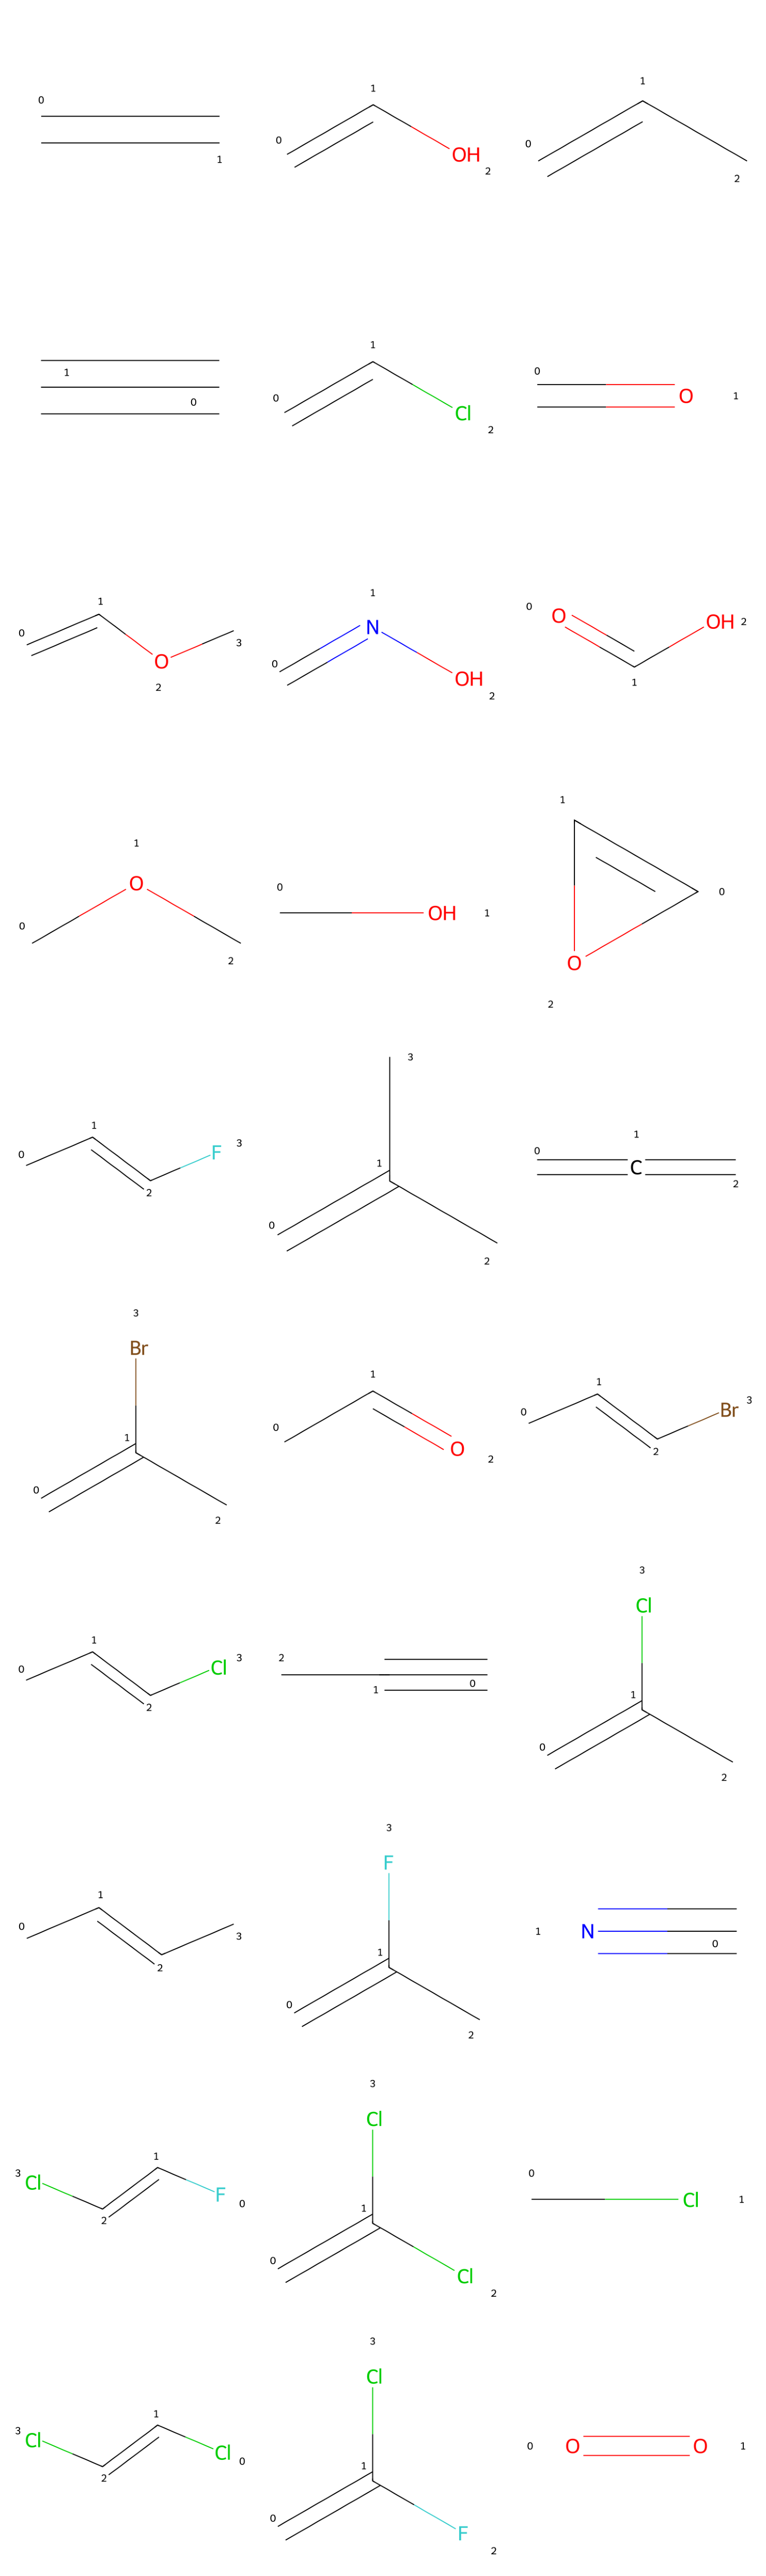

In [9]:
# Visualisation des 30 premières molécules dans l'ordre de découverte
N_SHOW = 30
to_show = [entry["smiles"] for entry in discovery_log[:N_SHOW]]

print(f"Molécules 0 à {N_SHOW - 1} dans l'ordre de découverte :\n")
for entry in discovery_log[:N_SHOW]:
    print(f"  rank {entry['rank']:>4}  wave {entry['wave']:>3}  {entry['smiles']:<40}  ← {entry['parent']}")

svgs = [mol_to_svg(Molecule(smi)) for smi in to_show]
draw_multiple_svgs_in_matplotlib(svgs)

## Statistiques Hückel

In [10]:
huckel_eval = Huckel()
rows = []

for entry in discovery_log:
    smi = entry["smiles"]
    mol = Molecule(smi)
    try:
        result = huckel_eval.evaluate(mol)
        rows.append({
            "rank":           entry["rank"],
            "wave":           entry["wave"],
            "parent":         entry["parent"],
            "smiles":         smi,
            "n_pi_electrons": result.n_pi_electrons,
            "homo_lambda":    result.homo_lambda,
            "lumo_lambda":    result.lumo_lambda,
            "gap_lambda":     result.gap_lambda,
            "n_orbitals":     len(result.eigenvalues_lambda),
        })
    except EvaluationError as e:
        rows.append({"rank": entry["rank"], "smiles": smi, "erreur": str(e)})

df = pd.DataFrame(rows)
df

,rank,wave,parent,smiles,n_pi_electrons,homo_lambda,lumo_lambda,gap_lambda,n_orbitals,erreur
0,0,0.0,None,C=C,2.0,1.000000,-1.000000,2.000000,2.0,NaN
1,1,1.0,C=C,C=CO,4.0,0.840741,-1.071267,1.912008,3.0,NaN
2,2,1.0,C=C,C=CC,4.0,0.814472,-1.082631,1.897103,3.0,NaN
3,3,1.0,C=C,C#C,2.0,1.000000,-1.000000,2.000000,2.0,NaN
4,4,1.0,C=C,C=CCl,4.0,0.766320,-1.077957,1.844277,3.0,NaN
...,...,...,...,...,...,...,...,...,...,...
4224,4224,10.0,C=CNC(=O)NN,CC=CNC(=O)NN,12.0,0.425619,-1.035926,1.461546,8.0,NaN
4225,4225,10.0,CC1=C(C)N(C)C(=O)N1,CC1=C(C)N(C)C(=O)N1C,16.0,0.259854,-1.253599,1.513453,10.0,NaN
4226,4226,10.0,CN1C(=S)SC=C1O,CC1=C(O)N(C)C(=S)S1,14.0,0.244613,-1.063864,1.308477,9.0,NaN
4227,4227,10.0,CN1C(=S)SC=C1O,NN1C(=S)SC=C1O,12.0,0.237076,-1.066481,1.303556,8.0,NaN


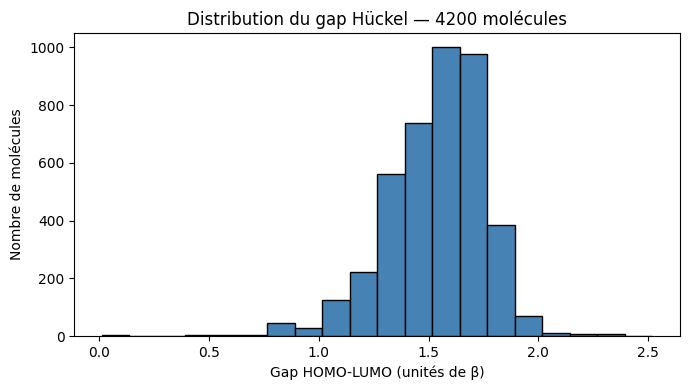

In [11]:
import matplotlib.pyplot as plt

gaps = df["gap_lambda"].dropna()
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(gaps, bins=20, edgecolor="black", color="steelblue")
ax.set_xlabel("Gap HOMO-LUMO (unités de β)")
ax.set_ylabel("Nombre de molécules")
ax.set_title(f"Distribution du gap Hückel — {len(gaps)} molécules")
plt.tight_layout()
plt.show()

## Export

In [12]:
output_dir = os.path.join(project_root, "output")
os.makedirs(output_dir, exist_ok=True)

can_start = Molecule(STARTING_SMILES).get_representation(MolecularGraph).canonical_smiles
safe_start = can_start.replace("/", "").replace("\\", "")
out_path = os.path.join(
    output_dir,
    f"huckel_parallel_{safe_start}_max{MAX_HEAVY_ATOMS}_t{int(MAX_SECONDS)}s_cpu{N_CPU}.txt",
)

with open(out_path, "w", encoding="utf-8") as fh:
    for entry in discovery_log:
        fh.write(entry["smiles"] + "\n")

print(f"{len(discovery_log)} molécules sauvegardées dans : {out_path}")

4229 molécules sauvegardées dans : /Users/LeaClautour/Desktop/LeaMol/output/huckel_parallel_C=C_max10_t60s_cpu3.txt
